In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import pandas as pd

/tmp/ipykernel_21768/329212259.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis', N)


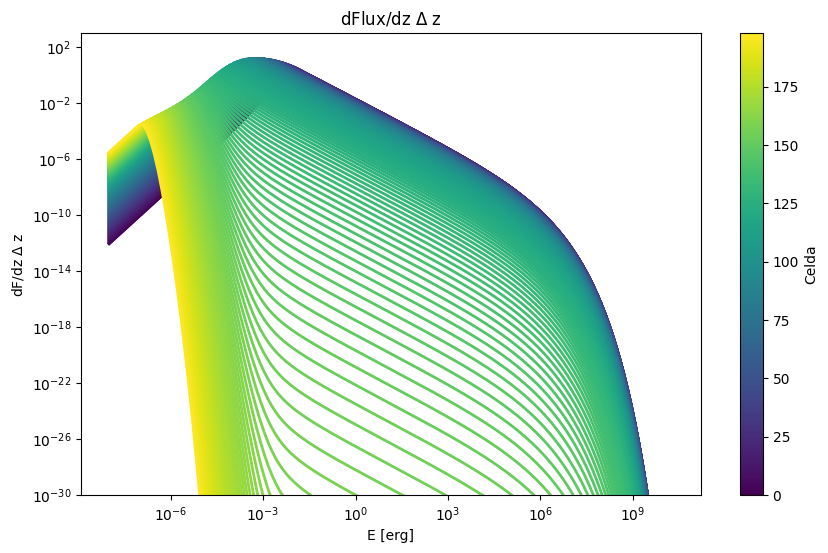

In [31]:


# Cargar los datos
data = np.loadtxt('./../Code/dFlux_dz.dat')

# Extraer el eje x y las columnas de datos
x = data[:, 0]
y_values = data[:, 1:]
# Número de columnas
N = y_values.shape[1]

# Crear el colormap Viridis
cmap = cm.get_cmap('viridis', N)
norm = mcolors.Normalize(vmin=0, vmax=N-1)

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(10, 6))

# Graficar todas las curvas con colores del colormap
for i in range(N):
    ax.plot(x, y_values[:, i], color=cmap(norm(i)), linewidth=2)

# Agregar la barra de colores
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # Necesario para la colorbar
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label('Celda')  # Etiqueta de la colorbar

# Etiquetas y título
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1e-30,1e3)
ax.set_xlabel(r'E [erg]')  # Ajustar según los datos
ax.set_ylabel(r'dF/dz $\Delta$ z')  # Ajustar según los datos
ax.set_title(r'dFlux/dz $\Delta$ z')

plt.show()

In [ ]:


# Cargar los datos
data = np.loadtxt('./../Code/Ne_cuts.dat')

# Extraer columnas
E = data[:, 0]  # Primer columna
N = data[:, 1]  # Segunda columna
Z = data[:, 2]  # Tercera columna

data2 = np.loadtxt('./../Code/quant_FF.dat')
# Encontrar valores únicos de E y Z
r=data2[:, 2]
Deltaz=data2[:, -2]

E_unique = np.unique(E)
Z_unique = np.unique(Z)

# Crear una matriz de N con dimensiones (len(E_unique), len(Z_unique))
N_matrix = np.full((len(E_unique), len(Z_unique)), np.nan)  # Usamos NaN para identificar valores faltantes

# Rellenar la matriz
for e, n, z in zip(E, N, Z):
    i = np.where(E_unique == e)[0][0]
    j = np.where(Z_unique == z)[0][0]
    N_matrix[i, j] = n

N_matrix
# Convert the matrix to a DataFrame
df = pd.DataFrame(N_matrix, index=E_unique, columns=Z_unique)

print(E_unique[1])
Deltaz[:]

1.8612468694701466e-06


array([2.65433372e+02, 2.05096731e+02, 1.80155117e+02, 1.67166017e+02,
       1.59935418e+02, 1.56041538e+02, 1.54326517e+02, 1.54163946e+02,
       1.55185901e+02, 1.57163812e+02, 1.59950309e+02, 1.63448348e+02,
       1.67593711e+02, 1.72344564e+02, 1.77674944e+02, 1.83570565e+02,
       1.90026040e+02, 1.97042990e+02, 2.04628749e+02, 2.12795452e+02,
       2.21559405e+02, 2.30940636e+02, 2.40962595e+02, 2.51651947e+02,
       2.63038446e+02, 2.75154873e+02, 2.88037011e+02, 3.01723668e+02,
       3.16256727e+02, 3.31681224e+02, 3.48045449e+02, 3.65401071e+02,
       3.83803281e+02, 4.03310952e+02, 4.23986822e+02, 4.45897691e+02,
       4.69114634e+02, 4.93713238e+02, 5.19773851e+02, 5.47381853e+02,
       5.76627944e+02, 6.07608456e+02, 6.40425683e+02, 6.75188229e+02,
       7.12011392e+02, 7.51017556e+02, 7.92336620e+02, 8.36106453e+02,
       8.82473370e+02, 9.31592649e+02, 9.83629071e+02, 1.03875750e+03,
       1.09716350e+03, 1.15904397e+03, 1.22460788e+03, 1.29407694e+03,
      

/tmp/ipykernel_13544/3803663465.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis', N)


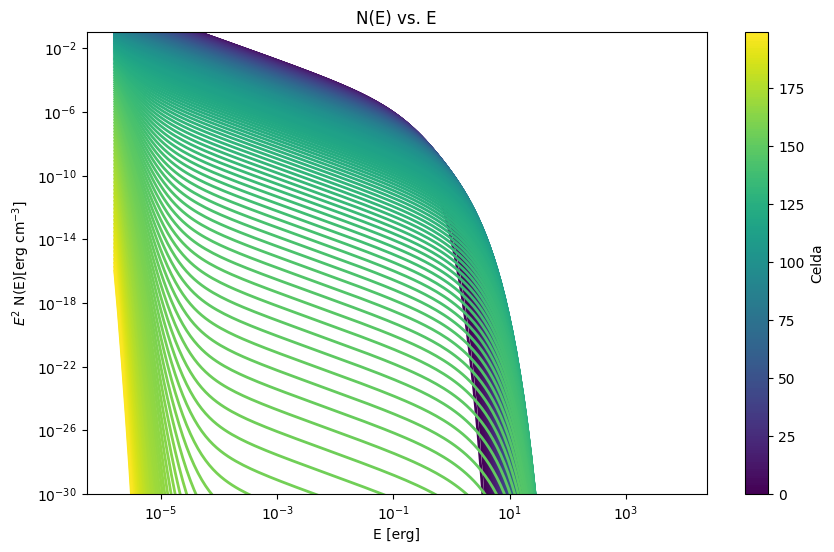

In [6]:
# Cargar los datos
data = np.loadtxt('./../Code/Ne_cuts.dat')

# Extraer el eje x y las columnas de datos
x = data[:, 0]
y_values = data[:, 1:]
# Número de columnas
N = len(Z_unique)

# Crear el colormap Viridis
cmap = cm.get_cmap('viridis', N)
norm = mcolors.Normalize(vmin=0, vmax=N-1)

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(10, 6))

# Graficar todas las curvas con colores del colormap
for i in range(N):
    ax.plot(E_unique, E_unique**2*df.iloc[:, i], color=cmap(norm(i)), linewidth=2)

# Agregar la barra de colores
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # Necesario para la colorbar
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label('Celda')  # Etiqueta de la colorbar

# Etiquetas y título
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1e-30,1e-1)
ax.set_xlabel(r'E [erg]')  # Ajustar según los datos
ax.set_ylabel(r'$E^2$ N(E)[erg cm$^{-3}$]')  # Ajustar según los datos
ax.set_title(r'N(E) vs. E')

plt.show()

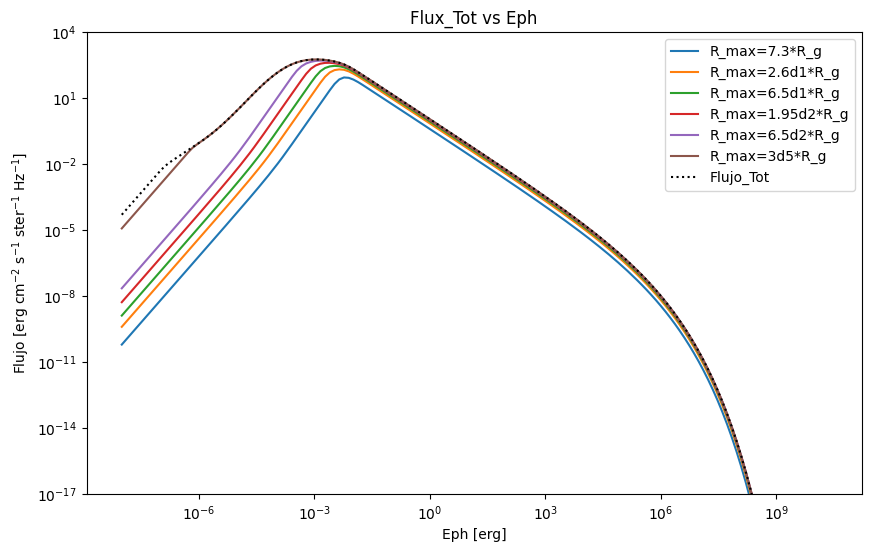

In [33]:
# Read the data from Flux.dat
df_flux = pd.read_csv('./../Code/Flux.dat', sep='\s+', header=0)

# Plot the first and last column
            
plt.figure(figsize=(10, 6))
plt.plot(df_flux['Eph/eV'], df_flux['Flujo_1'], label='R_max=7.3*R_g')
plt.plot(df_flux['Eph/eV'], df_flux['Flujo_2'], label='R_max=2.6d1*R_g')
plt.plot(df_flux['Eph/eV'], df_flux['Flujo_3'], label='R_max=6.5d1*R_g')
plt.plot(df_flux['Eph/eV'], df_flux['Flujo_4'], label='R_max=1.95d2*R_g')
plt.plot(df_flux['Eph/eV'], df_flux['Flujo_5'], label='R_max=6.5d2*R_g')
plt.plot(df_flux['Eph/eV'], df_flux['Flujo_6'], label='R_max=3d5*R_g')
plt.plot(df_flux['Eph/eV'], df_flux['Flujo_Tot'], label='Flujo_Tot', linestyle=':', color='black')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Eph [erg]')
plt.ylabel('Flujo [erg cm$^{-2}$ s$^{-1}$ ster$^{-1}$ Hz$^{-1}$]')
plt.title('Flux_Tot vs Eph')
plt.ylim(1e-17, 1e4)
plt.legend()
plt.show()